# Grummon et al. (2025) — Front-of-Package (FOP) Nutrition Labels RCT Benchmark

Out-of-distribution Marketing / Consumer Behavior benchmark from Grummon et al. (2025, *JAMA Network Open* 8(10):e2537389, `doi:10.1001/jamanetworkopen.2025.37389`), **"Nutrition Info and Other Front-of-Package Labels and Simulated Food and Beverage Purchases: A Randomized Clinical Trial"** ($N = 5,636$ US primary grocery shoppers randomized across 6 front-of-package labeling arms).

### Source Files & Provenance (in `code/nutrition/`)
1. **Main Paper PDF**: `nutrition/papers/Nutrition Info and Other Front-of-Package Labels and Simulated Food and Beverage Purchases.pdf`
   - **Methods / Procedures (pp. 2–3) & Figure 1 (p. 4)**: Visual layout, colors, and wording of the 6 FOP labeling systems (`Nutrition Info`, `Positive`, `Positive plus Nutrition Info`, `High In`, `Positive plus High In`, `Spectrum`).
   - **Table 1 (pp. 6–7)**: Participant demographic categories.
2. **Supplement 1 PDF (IRB Protocol)**: `nutrition/Nutrition Info and Other Front-of-Package Labels and Simulated Food and Beverage Purchases/zoi251032supp1_prod_1760453471.94614.pdf`
   - **Section 3.3.6.2 & Figure 3 (p. 1)**: Experimental conditions and label examples.
   - **Section 3.3.6.3 (p. 2)**: Store scraped from Hannaford.com with Guiding Stars and Nutrition Facts data.
3. **Supplement 2 PDF (eFigure & eTables 1–9)**: `nutrition/Nutrition Info and Other Front-of-Package Labels and Simulated Food and Beverage Purchases/zoi251032supp2_prod_1760453471.95614.pdf`
   - **eTable 1 (p. 3)**: Exact rules and FDA Daily Value (`%DV`) thresholds for assigning `Positive`, `Nutrition Info`, `High In`, and `Spectrum` labels to each product.
   - **eTable 2 (pp. 4–5)**: Store catalog departments and product counts.
   - **eTable 3 (pp. 5–11)**: Complete Qualtrics survey instrument, programming notes (`[display labels from participants randomly assigned trial arm]`), product pairs, and response scales.
   - **eTable 9 (p. 18)**: Trial treatment effects on consumer understanding (`idbev`–`idmeal`), noticing/using labels, negative emotions, perceived helpfulness/understandability/trustworthiness, and policy support.
4. **Dataset & Codebook**: `nutrition/Nutrition Info and Other Front-of-Package Labels and Simulated Food and Beverage Purchases/ParentFile_wide.csv` (and `.dta`) + `DataDictionary.docx`
   - Exact column names, numeric coding (`1..5`, `1..3`, `0/1`), and recodes (`rnoticed_trial`, `rused_trial`, `racecat`, `scr_litall`).

In [1]:
import gc, json, sys, traceback
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from cycler import cycler
from IPython.display import display
from tqdm.auto import tqdm

sys.path.insert(0, "kev")
from models.kev_pointer import KevPointerModel

LANCET_PALETTE = ["#1B365D", "#9E2A2B", "#2E8B78", "#D9822B", "#6F5091", "#4A6F8A"]
plt.rcParams["axes.prop_cycle"] = cycler(color=LANCET_PALETTE)

DATA_PATH = Path(
    "nutrition/Nutrition Info and Other Front-of-Package Labels and Simulated Food and Beverage Purchases/ParentFile_wide.csv"
)
raw_df = pd.read_csv(DATA_PATH)
print(f"Loaded {len(raw_df):,} respondents x {raw_df.shape[1]} columns from {DATA_PATH.name}")
raw_df[["participantid", "foplcond", "age", "gender", "educ", "income", "idbev", "rhelp", "rsupport"]].head()

Loaded 5,636 respondents x 87 columns from ParentFile_wide.csv


,participantid,foplcond,age,gender,educ,income,idbev,rhelp,rsupport
0,000EDE20B49148C6B225823CC6D64AF7,Positive,49,1.0,3.0,6.0,3.0,5.0,4.0
1,0019A30A1F2C41C685A9CE494181EED2,Positive+NutritionInfo,33,1.0,5.0,7.0,1.0,4.0,4.0
2,001A93FD6D314F7BBD9CD777D31B462E,Positive+HighIn,20,3.0,3.0,3.0,1.0,4.0,5.0
3,001DDAF9DA1F46618158D81D24E81EEB,HighIn,48,1.0,2.0,1.0,1.0,5.0,4.0
4,002D321B2814496DA6BDA3438A04F646,Spectrum,52,2.0,5.0,6.0,1.0,1.0,5.0


## 1. Map Respondent Persona Attributes (`state`) and Consumer-Facing Label Manipulations (`criteria` / `instructions`)

In [2]:
# Age buckets match our US-ISSP training pipeline (train-9b.ipynb); raw `age` is restricted to whole numbers >= 18
# per Supplement 2, eTable 3 (p. 5, construct: Eligibility / Age).
AGE_BINS = [17, 29, 49, 64, 120]
AGE_LABELS = ["18-29", "30-49", "50-64", "65+"]

# `state` contains strictly respondent persona attributes (aligned with ISSP/SubPOP PERSONA_NAMES where overlapping).
# Source variables in ParentFile_wide.csv / DataDictionary.docx (pp. 2-4) & Supplement 2, eTable 3 (pp. 9-11):
PERSONA_NAMES = {
    "c_alphan": "Country",        # Eligibility: US adults (Main paper p. 2, Methods > Participants)
    "SEX": "Sex",                 # `gender` (DataDictionary.docx p. 2; eTable 3 p. 9)
    "AGE": "Age",                 # `age` (DataDictionary.docx p. 2; eTable 3 p. 5)
    "EDULEVEL": "Education",      # `educ` (DataDictionary.docx p. 3; eTable 3 p. 10)
    "US_INC": "Income",           # `income` (DataDictionary.docx p. 3; eTable 3 p. 11)
    "RACE": "Race",               # `racecat` (DataDictionary.docx p. 3; ParentFile_wide.dta `racecatlabels`)
    "HISPANIC": "Hispanic or Latino",                # `latino` (DataDictionary.docx p. 2; eTable 3 p. 9)
    "SNAP": "SNAP / Food Stamps recipient",          # `snap` (DataDictionary.docx p. 3)
    "NFPUSE": "Nutrition Facts label usage",         # `nfpuse` (DataDictionary.docx p. 3)
    "ONLINEAMT": "Share of groceries bought online", # `onlineamt` (DataDictionary.docx p. 3)
    "HEALTHLIT": "Nutrition literacy score",         # `scr_litall`: sum of 4 Newest Vital Sign items (DataDictionary.docx p. 3; eTable 3 pp. 10-11)
}

# Group-level visual-to-text manipulation shown on products in the store and displayed as pictures above the
# post-shopping label-evaluation questions (`[display labels from participants randomly assigned trial arm]`).
# Sources:
#   - Main paper, Figure 1 (p. 4, "Examples of Labels Tested in the Trial") & Methods > Procedures (pp. 2-3)
#   - Supplement 1, Section 3.3.6.2 & Figure 3 (p. 1, "Conditions for experiment")
#   - Supplement 2, eTable 1 (p. 3, "Criteria for Assigning Labels to Each Product") & eTable 3 (pp. 7-9)
#   - DataDictionary.docx (p. 1, variable `foplcond`: 1=HighIn, 2=NutritionInfo, 3=Positive, 4=Positive+HighIn, 5=Positive+NutritionInfo, 6=Spectrum)
FOPL_STIMULUS = {
    "Positive": (
        "Blue star badge showing '[* GOOD]' (1 star), '[** BETTER]' (2 stars), or '[*** BEST]' (3 stars) "
        "on qualifying products; no front-of-package label on other products."
    ),
    "NutritionInfo": (
        "White box with magnifying glass icon on all products reading 'Nutrition Info | Per serving | "
        "Saturated Fat: Low (green) / Med (yellow) / High (red) | "
        "Sodium: Low (green) / Med (yellow) / High (red) | "
        "Added Sugars: Low (green) / Med (yellow) / High (red) | FDA.gov'."
    ),
    "HighIn": (
        "White box with magnifying glass icon reading 'High In | [Saturated Fat / Sodium / Added Sugars] | FDA.gov' "
        "when a product is high in those nutrients; no front-of-package label on other products."
    ),
    "Positive+NutritionInfo": (
        "Blue star badge ('[* GOOD]', '[** BETTER]', or '[*** BEST]' when earned) alongside white box on all products "
        "reading 'Nutrition Info | Per serving | Saturated Fat: Low (green) / Med (yellow) / High (red) | "
        "Sodium: Low (green) / Med (yellow) / High (red) | Added Sugars: Low (green) / Med (yellow) / High (red) | FDA.gov'."
    ),
    "Positive+HighIn": (
        "Blue star badge ('[* GOOD]', '[** BETTER]', or '[*** BEST]' when earned) alongside white box "
        "reading 'High In | [Saturated Fat / Sodium / Added Sugars] | FDA.gov' (when high in those nutrients); "
        "no front-of-package label on other products."
    ),
    "Spectrum": (
        "Color-coded 1-to-5 star badge on all products reading '[* POOR]' (1 star, red), '[** FAIR]' (2 stars, orange), "
        "'[*** GOOD]' (3 stars, yellow), '[**** BETTER]' (4 stars, light green), or '[***** BEST]' (5 stars, dark green)."
    ),
}

# Product-level visual-to-text labels for the 6 product-comparison questions (`idbev`..`idmeal`).
# Sources:
#   1) Exact product pairs & Qualtrics programming note (`[display labels from participants randomly assigned trial arm]`):
#      Supplement 2, eTable 3 (pp. 6-7, "Consumer Understanding - Identification of healthier product") &
#      DataDictionary.docx (pp. 3-4, variables `idbev`, `idbread`, `idcereal`, `idsoup`, `idsnack`, `idmeal`).
#   2) Label assignment rules (Supplement 2, eTable 1, p. 3):
#      - FDA Daily Values (DV) per serving: Saturated Fat = 20g, Sodium = 2,300mg, Added Sugars = 50g.
#      - `NutritionInfo` thresholds: Low (<5% DV: <1g sat fat, <115mg sodium, <2.5g added sugars; green),
#        Med (5% to <20% DV: 1-3.9g sat fat, 115-459mg sodium, 2.5-9.9g added sugars; yellow),
#        High (>=20% DV: >=4g sat fat, >=460mg sodium, >=10g added sugars; red).
#      - `HighIn` threshold: Displayed only when >=20% DV per serving on Saturated Fat, Sodium, or Added Sugars.
#      - `Positive` (Guiding Stars 1-3 stars: Good/Better/Best) & `Spectrum` (Expanded Guiding Stars 1-5 stars:
#        1=Poor, 2=Fair for 0-star items; 3=Good, 4=Better, 5=Best for 1-, 2-, 3-star items).
# Tuple format per product: (positive_badge, nutrition_info_badge, high_in_badge, spectrum_badge)
PRODUCT_BASE_LABELS = {
    # idbev (eTable 3 p. 6): Ocean Spray 100% Cranberry juice (0g sat fat, 15mg Na, 0g added sugar) vs.
    # Ocean Spray Cranberry Juice Cocktail (0g sat fat, 35mg Na, 25g [50% DV] added sugar)
    "idbev": {
        "Ocean Spray 100% Cranberry juice": (
            None,
            "Nutrition Info Per serving - Saturated Fat: Low (green), Sodium: Low (green), Added Sugars: Low (green) | FDA.gov",
            None,
            "[** FAIR (2 stars, orange)]",
        ),
        "Ocean Spray Cranberry Juice Cocktail": (
            None,
            "Nutrition Info Per serving - Saturated Fat: Low (green), Sodium: Low (green), Added Sugars: High (red) | FDA.gov",
            "High In: Added Sugars | FDA.gov",
            "[* POOR (1 star, red)]",
        ),
    },
    # idbread (eTable 3 p. 7): Mission Extra Thin Corn Tortillas (0g sat fat, 20mg Na, 0g added sugar) vs.
    # Mission Flour Burrito Tortillas (1.5g [8% DV] sat fat, 480-620mg [>=21% DV] Na, 1g added sugar)
    "idbread": {
        "Mission Extra Thin Corn Tortillas": (
            "[* GOOD (1 star, blue)]",
            "Nutrition Info Per serving - Saturated Fat: Low (green), Sodium: Low (green), Added Sugars: Low (green) | FDA.gov",
            None,
            "[*** GOOD (3 stars, yellow)]",
        ),
        "Mission Flour Burrito Tortillas": (
            None,
            "Nutrition Info Per serving - Saturated Fat: Med (yellow), Sodium: High (red), Added Sugars: Low (green) | FDA.gov",
            "High In: Sodium | FDA.gov",
            "[* POOR (1 star, red)]",
        ),
    },
    # idcereal (eTable 3 p. 7): Post Selects Great Grains Crunchy Pecans (0.5g sat fat, 150mg [7% DV] Na, 9g [18% DV] added sugar) vs.
    # General Mills Chocolate Chex Gluten Free Cereal (0.5g sat fat, 240mg [10% DV] Na, 10g [20% DV] added sugar)
    "idcereal": {
        "Post Selects Great Grains Crunchy Pecans": (
            "[* GOOD (1 star, blue)]",
            "Nutrition Info Per serving - Saturated Fat: Low (green), Sodium: Med (yellow), Added Sugars: Med (yellow) | FDA.gov",
            None,
            "[*** GOOD (3 stars, yellow)]",
        ),
        "General Mills Chocolate Chex Gluten Free Cereal": (
            None,
            "Nutrition Info Per serving - Saturated Fat: Low (green), Sodium: Med (yellow), Added Sugars: High (red) | FDA.gov",
            "High In: Added Sugars | FDA.gov",
            "[** FAIR (2 stars, orange)]",
        ),
    },
    # idsoup (eTable 3 p. 7): Campbell's Healthy Request Chunk Sirloin Burger Soup (1g [5% DV] sat fat, 410mg [18% DV] Na, 1g added sugar) vs.
    # Dinty Moore Beef Stew (2.5g [13% DV] sat fat, 980mg [43% DV] Na, 0g added sugar)
    "idsoup": {
        "Campbell's Healthy Request Chunk Sirloin Burger Soup": (
            "[* GOOD (1 star, blue)]",
            "Nutrition Info Per serving - Saturated Fat: Med (yellow), Sodium: Med (yellow), Added Sugars: Low (green) | FDA.gov",
            None,
            "[*** GOOD (3 stars, yellow)]",
        ),
        "Dinty Moore Beef Stew": (
            None,
            "Nutrition Info Per serving - Saturated Fat: Med (yellow), Sodium: High (red), Added Sugars: Low (green) | FDA.gov",
            "High In: Sodium | FDA.gov",
            "[* POOR (1 star, red)]",
        ),
    },
    # idsnack (eTable 3 p. 7): Sun Chips Original multigrain snacks (0.5g sat fat, 140mg [6% DV] Na, 2g [4% DV] added sugar) vs.
    # Nutella & Go! Cup (4g [20% DV] sat fat, 115mg [5% DV] Na, 21g [42% DV] added sugar)
    "idsnack": {
        "Sun Chips Original multigrain snacks": (
            None,
            "Nutrition Info Per serving - Saturated Fat: Low (green), Sodium: Med (yellow), Added Sugars: Low (green) | FDA.gov",
            None,
            "[** FAIR (2 stars, orange)]",
        ),
        "Nutella & Go! Cup": (
            None,
            "Nutrition Info Per serving - Saturated Fat: High (red), Sodium: Med (yellow), Added Sugars: High (red) | FDA.gov",
            "High In: Saturated Fat, Added Sugars | FDA.gov",
            "[* POOR (1 star, red)]",
        ),
    },
    # idmeal (eTable 3 p. 7): Healthy Choice Cafe Steamers Chicken Marinara (1g [5% DV] sat fat, 440mg [19% DV] Na, 2g [4% DV] added sugar) vs.
    # Lean Cuisine Turkey with Dressing (1g [5% DV] sat fat, 590mg [26% DV] Na, 4g [8% DV] added sugar)
    "idmeal": {
        "Healthy Choice Cafe Steamers Chicken Marinara": (
            "[* GOOD (1 star, blue)]",
            "Nutrition Info Per serving - Saturated Fat: Med (yellow), Sodium: Med (yellow), Added Sugars: Low (green) | FDA.gov",
            None,
            "[*** GOOD (3 stars, yellow)]",
        ),
        "Lean Cuisine Turkey with Dressing": (
            None,
            "Nutrition Info Per serving - Saturated Fat: Med (yellow), Sodium: High (red), Added Sugars: Med (yellow) | FDA.gov",
            "High In: Sodium | FDA.gov",
            "[** FAIR (2 stars, orange)]",
        ),
    },
}


def format_product_label(qid, product_name, arm):
    pos_b, ninfo_b, highin_b, spec_b = PRODUCT_BASE_LABELS[qid][product_name]
    if arm == "Positive":
        badge = pos_b
    elif arm == "NutritionInfo":
        badge = ninfo_b
    elif arm == "HighIn":
        badge = highin_b
    elif arm == "Positive+NutritionInfo":
        badge = f"{pos_b}; {ninfo_b}" if pos_b is not None else ninfo_b
    elif arm == "Positive+HighIn":
        parts = [b for b in (pos_b, highin_b) if b is not None]
        badge = "; ".join(parts) if parts else None
    elif arm == "Spectrum":
        badge = spec_b
    else:
        raise ValueError(f"Unexpected arm {arm!r}")

    if badge is None:
        return "Front-of-package label: None"
    return f"Front-of-package label: {badge}"


def build_product_criteria(qid, option_texts, arm):
    p1, p2, same_opt = option_texts
    return {
        p1: format_product_label(qid, p1, arm),
        p2: format_product_label(qid, p2, arm),
        same_opt: None,
    }


# Demographic value mappings from DataDictionary.docx (pp. 2-3), ParentFile_wide.dta value labels, and Supplement 2, eTable 3 (pp. 9-11):
# `gender`: 1=Woman, 2=Man, 3=Non-binary, 4=Prefer to self-describe (mapped to Female/Male to match ISSP/SubPOP SEX labels)
GENDER_MAP = {1.0: "Female", 2.0: "Male", 3.0: "Non-binary", 4.0: "Other"}
# `latino`: 1=Yes, 0=No (DataDictionary.docx p. 2)
LATINO_MAP = {0.0: "No", 1.0: "Yes"}
# `racecat`: ParentFile_wide.dta `racecatlabels` & DataDictionary.docx p. 3
RACE_MAP = {
    "Amer Ind AK Native": "American Indian or Alaska Native",
    "Asian": "Asian",
    "Black": "Black or African American",
    "Native Hawaiian or Pacific Islander": "Native Hawaiian or Pacific Islander",
    "White": "White",
    "Other or multi-racial": "Other or multi-racial",
}
# `educ`: 1..6 (DataDictionary.docx p. 3; Supplement 2, eTable 3 p. 10)
EDUC_MAP = {
    1.0: "Less than high school",
    2.0: "High school graduate (or GED)",
    3.0: "Some college or technical school",
    4.0: "Associate's degree",
    5.0: "Bachelor's degree",
    6.0: "Graduate or professional degree",
}
# `income`: 1..10 (DataDictionary.docx p. 3; Supplement 2, eTable 3 p. 11)
INCOME_MAP = {
    1.0: "Less than $10,000",
    2.0: "$10,000 - $14,999",
    3.0: "$15,000 - $24,999",
    4.0: "$25,000 - $34,999",
    5.0: "$35,000 - $49,999",
    6.0: "$50,000 - $74,999",
    7.0: "$75,000 - $99,999",
    8.0: "$100,000 - $149,999",
    9.0: "$150,000 - $199,999",
    10.0: "$200,000 or more",
}
# `snap`: 1=Yes, 0=No, 2=Don't know (DataDictionary.docx p. 3)
SNAP_MAP = {0.0: "No", 1.0: "Yes", 2.0: "Don't know"}
# `nfpuse`: 1=Never .. 5=Always (DataDictionary.docx p. 3)
NFPUSE_MAP = {1.0: "Never", 2.0: "Rarely", 3.0: "Sometimes", 4.0: "Most of the time", 5.0: "Always"}
# `onlineamt`: 1=Less than 25% .. 4=75% or more (DataDictionary.docx p. 3)
ONLINE_MAP = {1.0: "Less than 25%", 2.0: "25-49%", 3.0: "50-74%", 4.0: "75% or more"}
# `scr_litall`: sum of scr_lit1..scr_lit4 (0..4 correct on Newest Vital Sign ice cream label; DataDictionary.docx p. 3; eTable 3 pp. 10-11)
HEALTHLIT_MAP = {i: f"{i} out of 4" for i in range(5)}


def strict_map(series, mapping, col_name):
    out = []
    for val in series:
        if pd.isna(val):
            out.append(None)
        else:
            if val not in mapping:
                raise ValueError(f"{col_name}: unexpected value {val!r}")
            out.append(mapping[val])
    return pd.Series(out, index=series.index, dtype=object)


for arm_val in raw_df["foplcond"]:
    if arm_val not in FOPL_STIMULUS:
        raise ValueError(f"Unexpected foplcond value {arm_val!r}")

age_num = pd.to_numeric(raw_df["age"], errors="raise")
age_bucketed = pd.cut(age_num, bins=AGE_BINS, labels=AGE_LABELS).astype(object)
if int(age_bucketed.isna().sum()) != int(raw_df["age"].isna().sum()):
    raise ValueError("Some non-missing age values fell outside AGE_BINS")

resp_df = pd.DataFrame({
    "participantid": raw_df["participantid"],
    "arm": raw_df["foplcond"],
    "c_alphan": "United States",
    "SEX": strict_map(raw_df["gender"], GENDER_MAP, "gender"),
    "AGE": age_bucketed,
    "EDULEVEL": strict_map(raw_df["educ"], EDUC_MAP, "educ"),
    "US_INC": strict_map(raw_df["income"], INCOME_MAP, "income"),
    "RACE": strict_map(raw_df["racecat"], RACE_MAP, "racecat"),
    "HISPANIC": strict_map(raw_df["latino"], LATINO_MAP, "latino"),
    "SNAP": strict_map(raw_df["snap"], SNAP_MAP, "snap"),
    "NFPUSE": strict_map(raw_df["nfpuse"], NFPUSE_MAP, "nfpuse"),
    "ONLINEAMT": strict_map(raw_df["onlineamt"], ONLINE_MAP, "onlineamt"),
    "HEALTHLIT": strict_map(raw_df["scr_litall"], HEALTHLIT_MAP, "scr_litall"),
})

# Response scales from DataDictionary.docx (pp. 2-4) and Supplement 2, eTable 3 (pp. 6-9):
AGREE_5 = ["Strongly disagree", "Somewhat disagree", "Neither agree nor disagree", "Somewhat agree", "Strongly agree"]
EXTENT_5 = ["Not at all", "Very little", "Somewhat", "Quite a bit", "A great deal"]
TRUST_5 = ["Completely distrust", "Somewhat distrust", "Neither trust nor distrust", "Somewhat trust", "Completely trust"]
SUPPORT_5 = ["Strongly oppose", "Somewhat oppose", "Neither oppose nor support", "Somewhat support", "Strongly support"]
YES_NO_CODES = [0.0, 1.0]
YES_NO_TEXTS = ["No", "Yes"]
CODES_3 = [1.0, 2.0, 3.0]
CODES_5 = [1.0, 2.0, 3.0, 4.0, 5.0]

HEALTHIER_PROMPT = (
    "Click on the product you think is healthier, or click 'They're the same' "
    "if you think the two products are equally healthy."
)

# 21 survey items from DataDictionary.docx (pp. 2-4) & Supplement 2, eTable 3 (pp. 6-9):
QUESTIONS = [
    # 1) 6 Product Healthfulness Choice Tasks (eTable 3 pp. 6-7; DataDictionary.docx pp. 3-4)
    #    Option 1 is always the healthier product (`scr_id*` = 1 if response == 1, 0 otherwise).
    ("idbev", "choice", HEALTHIER_PROMPT, CODES_3, ["Ocean Spray 100% Cranberry juice", "Ocean Spray Cranberry Juice Cocktail", "They're the same"]),
    ("idbread", "choice", HEALTHIER_PROMPT, CODES_3, ["Mission Extra Thin Corn Tortillas", "Mission Flour Burrito Tortillas", "They're the same"]),
    ("idcereal", "choice", HEALTHIER_PROMPT, CODES_3, ["Post Selects Great Grains Crunchy Pecans", "General Mills Chocolate Chex Gluten Free Cereal", "They're the same"]),
    ("idsoup", "choice", HEALTHIER_PROMPT, CODES_3, ["Campbell's Healthy Request Chunk Sirloin Burger Soup", "Dinty Moore Beef Stew", "They're the same"]),
    ("idsnack", "choice", HEALTHIER_PROMPT, CODES_3, ["Sun Chips Original multigrain snacks", "Nutella & Go! Cup", "They're the same"]),
    ("idmeal", "choice", HEALTHIER_PROMPT, CODES_3, ["Healthy Choice Cafe Steamers Chicken Marinara", "Lean Cuisine Turkey with Dressing", "They're the same"]),
    # 2) 2 Binary Label Notice / Use Tasks (eTable 3 p. 8; DataDictionary.docx p. 4)
    #    `rnoticed_trial` recodes `noticed_trial` (1=Yes, 0=No/Not sure); `rused_trial` is shown to those who noticed (1=Yes, 0=No).
    ("rnoticed_trial", "choice", "When you were selecting foods and beverages in the shopping task, did you notice any other nutrition labels next to the products (other than the Nutrition Facts Panel)?", YES_NO_CODES, YES_NO_TEXTS),
    ("rused_trial", "choice", "While you were shopping, did you use these other nutrition labels to decide which foods and beverages to select?", YES_NO_CODES, YES_NO_TEXTS),
    # 3) 10 Label Perception, Policy Support, Elaboration & Affect Likert Scales (eTable 3 pp. 7-9; DataDictionary.docx p. 4)
    ("elaborationhealth", "score", "When you were selecting foods and beverages in the shopping task, how much did you think about the overall healthfulness of the products?", CODES_5, EXTENT_5),
    ("raffect_worried", "score", "How much do these labels make you feel worried?", CODES_5, EXTENT_5),
    ("raffect_scared", "score", "How much do these labels make you feel scared?", CODES_5, EXTENT_5),
    ("raffect_guilty", "score", "How much do these labels make you feel guilty?", CODES_5, EXTENT_5),
    ("raffect_ashamed", "score", "How much do these labels make you feel ashamed?", CODES_5, EXTENT_5),
    ("raffect_sad", "score", "How much do these labels make you feel sad?", CODES_5, EXTENT_5),
    ("rhelp", "score", "How much do you agree or disagree with the following statement: These labels would help me choose healthier foods and beverages.", CODES_5, AGREE_5),
    ("runderstand", "score", "How much do you agree or disagree with the following statement: It is easy to understand the information in these labels.", CODES_5, AGREE_5),
    ("rtrust", "score", "How much do you trust or distrust the information in these labels?", CODES_5, TRUST_5),
    ("rsupport", "score", "Would you oppose or support a policy requiring these labels on foods and beverages?", CODES_5, SUPPORT_5),
    # 4) 3 Store Realism & Shopping Behavior Scales (DataDictionary.docx p. 2: `feltreal`, `picksimilar`, `similarusual`)
    ("feltreal", "score", "This online grocery store felt like a real online grocery store.", CODES_5, AGREE_5),
    ("picksimilar", "score", "If I completed this shopping task in an actual store, I would pick similar products as I chose in this study.", CODES_5, AGREE_5),
    ("similarusual", "score", "The foods I selected in this online grocery store were similar to my usual grocery purchases.", CODES_5, AGREE_5),
]

long_frames = []
for v_name, q_type, q_text, codes, texts in QUESTIONS:
    valid_mask = raw_df[v_name].notna()
    sub = resp_df.loc[valid_mask].copy()
    ans = raw_df.loc[valid_mask, v_name]
    code_to_idx = {c: i for i, c in enumerate(codes)}
    one_hots = []
    for val in ans:
        if val not in code_to_idx:
            raise ValueError(f"{v_name}: unexpected answer {val!r}")
        vec = np.zeros(len(codes), dtype=np.float64)
        vec[code_to_idx[val]] = 1.0
        one_hots.append(vec)
    sub["v"] = v_name
    sub["qid"] = sub["arm"] + ":" + v_name
    sub["type"] = q_type
    sub["question"] = q_text
    sub["option_codes"] = [codes] * len(sub)
    sub["option_texts"] = [texts] * len(sub)
    sub["answer_code"] = ans.values
    sub["one_hot"] = one_hots
    long_frames.append(sub)

grummon_df = pd.concat(long_frames, ignore_index=True)
print(
    f"grummon_df: {len(grummon_df):,} respondent-answers across "
    f"{grummon_df['v'].nunique()} survey items x {grummon_df['arm'].nunique()} trial arms "
    f"({grummon_df['qid'].nunique()} arm-specific questions)"
)
grummon_df[["participantid", "arm", "SEX", "AGE", "EDULEVEL", "qid", "type", "answer_code"]].head()

grummon_df: 114,899 respondent-answers across 21 survey items x 6 trial arms (126 arm-specific questions)


,participantid,arm,SEX,AGE,EDULEVEL,qid,type,answer_code
0,000EDE20B49148C6B225823CC6D64AF7,Positive,Female,30-49,Some college or technical school,Positive:idbev,choice,3.0
1,0019A30A1F2C41C685A9CE494181EED2,Positive+NutritionInfo,Female,30-49,Bachelor's degree,Positive+NutritionInfo:idbev,choice,1.0
2,001A93FD6D314F7BBD9CD777D31B462E,Positive+HighIn,Non-binary,18-29,Some college or technical school,Positive+HighIn:idbev,choice,1.0
3,001DDAF9DA1F46618158D81D24E81EEB,HighIn,Female,30-49,High school graduate (or GED),HighIn:idbev,choice,1.0
4,002D321B2814496DA6BDA3438A04F646,Spectrum,Male,50-64,Bachelor's degree,Spectrum:idbev,choice,1.0


In [3]:
resp_df.loc[resp_df["HISPANIC"] == "Yes", "RACE"].value_counts(dropna=False)

RACE
White                                  410
Other or multi-racial                  103
Black or African American               43
American Indian or Alaska Native        14
Asian                                    8
None                                     1
Native Hawaiian or Pacific Islander      1
Name: count, dtype: int64

## 2. Build Test Records and Inspect `make_view(rec)` (Labels in `criteria` / `instructions`, Persona in `state`)

In [4]:
def make_record(sub_df, cols):
    if isinstance(sub_df, dict):
        row = sub_df
        human_dist = row["one_hot"]
        n = 1
    else:
        for c in cols:
            if sub_df[c].nunique(dropna=False) != 1:
                raise ValueError(f"sub_df must have a single value for {c!r}, got {sub_df[c].unique().tolist()}")
        row = sub_df.iloc[0]
        human_dist = np.stack(sub_df["one_hot"].values).mean(axis=0)
        n = len(sub_df)

    personas = {c: row[c] for c in cols if c != "c_alphan"}
    return {
        "qid": row["qid"],
        "arm": row["arm"],
        "v": row["v"],
        "type": row["type"],
        "question": row["question"],
        "option_texts": row["option_texts"],
        "country": row["c_alphan"],
        "personas": personas,
        "attribute": "+".join(personas.keys()) if personas else "none",
        "persona": ", ".join(f"{PERSONA_NAMES[c]}={v}" for c, v in personas.items()) if personas else "All",
        "n": n,
        "human_dist": human_dist,
    }


def build_persona_dataset(df, attr_sets=None, min_n=100):
    records = []
    for _, q_df in df.groupby("qid", sort=False):
        if attr_sets is None:
            for row in q_df.to_dict("records"):
                cols = [c for c in PERSONA_NAMES if c != "c_alphan" and pd.notna(row[c])]
                records.append(make_record(row, cols))
            continue
        sets = [[attr_sets]] if isinstance(attr_sets, str) else attr_sets
        for cols in sets:
            cols = [cols] if isinstance(cols, str) else list(cols)
            if not cols:
                if min_n is None or len(q_df) >= min_n:
                    records.append(make_record(q_df, cols))
                continue
            for _, sub_df in q_df.groupby(cols, sort=False, observed=True):
                if min_n is None or len(sub_df) >= min_n:
                    records.append(make_record(sub_df, cols))
    return records


def make_view(rec):
    qid = rec["qid"]
    v_name = rec["v"]
    arm = rec["arm"]
    q_type = rec["type"]
    option_texts = rec["option_texts"]
    human_dist = rec["human_dist"]

    # 1) `state` is strictly the respondent persona (identical convention to ISSP/SubPOP)
    state_lines = [f"{PERSONA_NAMES['c_alphan']}: {rec['country']}"]
    state_lines.extend(f"{PERSONA_NAMES[c]}: {v}" for c, v in rec["personas"].items())

    # 2) `criteria` (for idbev..idmeal) and `instructions` (for post-shopping items) carry the trial arm's label stimulus
    #    per Supplement 2, eTable 3 programming notes (`[display labels from participants randomly assigned trial arm]`).
    if v_name in PRODUCT_BASE_LABELS:
        instructions = rec["question"]
        criteria = build_product_criteria(v_name, option_texts, arm)
        target = {text: float(p) for text, p in zip(option_texts, human_dist)}
    elif q_type == "choice":
        instructions = f"Labels shown on products: {FOPL_STIMULUS[arm]}\n{rec['question']}"
        criteria = {text: None for text in option_texts}
        target = {text: float(p) for text, p in zip(option_texts, human_dist)}
    elif q_type == "score":
        instructions = f"Labels shown on products: {FOPL_STIMULUS[arm]}\n{rec['question']}"
        criteria = option_texts
        target = {str(i): float(p) for i, p in enumerate(human_dist)}
    else:
        raise ValueError(f"{qid}: unexpected question type {q_type!r}")

    return {
        "state": "\n".join(state_lines),
        "questions": {
            qid: {
                "type": q_type,
                "instructions": instructions,
                "criteria": criteria,
                "target": target,
            }
        },
    }


DEMO_COLS = [c for c in PERSONA_NAMES if c != "c_alphan"]

min_n = 30

# 1) Trial-arm main effect benchmark (country-only persona, 6 arms x 21 items = 126 records)
eval_records_arm = build_persona_dataset(grummon_df, attr_sets=[[]], min_n=min_n)
# 2) k=1 persona benchmark across all 6 arms (1 demographic attribute in `state`, n>=min_n)
eval_records_k1 = build_persona_dataset(grummon_df, attr_sets=[[c] for c in DEMO_COLS], min_n=min_n)

print(f"eval_records_arm (all US shoppers per arm, 6 arms x 21 items): {len(eval_records_arm):,}")
print(f"eval_records_k1  (1 persona attribute in state, n>={min_n})      : {len(eval_records_k1):,}")

print("\n--- Example 1a: Product Healthfulness Choice (Positive:idbev, Sex=Female) ---")
ex_pos = next(r for r in eval_records_k1 if r["qid"] == "Positive:idbev" and r["persona"] == "Sex=Female")
print(json.dumps(make_view(ex_pos), indent=2))

print("\n--- Example 1b: Product Healthfulness Choice (NutritionInfo:idbev, Sex=Female) ---")
ex_choice = next(r for r in eval_records_k1 if r["qid"] == "NutritionInfo:idbev" and r["persona"] == "Sex=Female")
print(json.dumps(make_view(ex_choice), indent=2))

print("\n--- Example 2: Label Perception Score (Spectrum:rhelp, Sex=Female) ---")
ex_score = next(r for r in eval_records_k1 if r["qid"] == "Spectrum:rhelp" and r["persona"] == "Sex=Female")
print(json.dumps(make_view(ex_score), indent=2))
# Fail-fast verification that all rendered views are pure ASCII
for _r in eval_records_arm + eval_records_k1:
    _s = json.dumps(make_view(_r), ensure_ascii=False)
    if not _s.isascii():
        raise ValueError(f"Non-ASCII character in make_view({_r['qid']}): {_s!r}")


eval_records_arm (all US shoppers per arm, 6 arms x 21 items): 126
eval_records_k1  (1 persona attribute in state, n>=30)      : 5,060

--- Example 1a: Product Healthfulness Choice (Positive:idbev, Sex=Female) ---
{
  "state": "Country: United States\nSex: Female",
  "questions": {
    "Positive:idbev": {
      "type": "choice",
      "instructions": "Click on the product you think is healthier, or click 'They're the same' if you think the two products are equally healthy.",
      "criteria": {
        "Ocean Spray 100% Cranberry juice": "Front-of-package label: None",
        "Ocean Spray Cranberry Juice Cocktail": "Front-of-package label: None",
        "They're the same": null
      },
      "target": {
        "Ocean Spray 100% Cranberry juice": 0.6358885017421603,
        "Ocean Spray Cranberry Juice Cocktail": 0.01916376306620209,
        "They're the same": 0.34494773519163763
      }
    }
  }
}

--- Example 1b: Product Healthfulness Choice (NutritionInfo:idbev, Sex=Female) ---

In [5]:
ex_score = next(r for r in eval_records_k1 if r["qid"] == "Spectrum:rhelp" and r["persona"] == "Sex=Female")
print(json.dumps(make_view(ex_score), indent=2))

ex_score = next(r for r in eval_records_k1 if r["qid"] == "Spectrum:rhelp" and r["persona"] == "Sex=Male")
print(json.dumps(make_view(ex_score), indent=2))

{
  "state": "Country: United States\nSex: Female",
  "questions": {
    "Spectrum:rhelp": {
      "type": "score",
      "instructions": "Labels shown on products: Color-coded 1-to-5 star badge on all products reading '[* POOR]' (1 star, red), '[** FAIR]' (2 stars, orange), '[*** GOOD]' (3 stars, yellow), '[**** BETTER]' (4 stars, light green), or '[***** BEST]' (5 stars, dark green).\nHow much do you agree or disagree with the following statement: These labels would help me choose healthier foods and beverages.",
      "criteria": [
        "Strongly disagree",
        "Somewhat disagree",
        "Neither agree nor disagree",
        "Somewhat agree",
        "Strongly agree"
      ],
      "target": {
        "0": 0.029304029304029304,
        "1": 0.12454212454212454,
        "2": 0.10805860805860806,
        "3": 0.489010989010989,
        "4": 0.2490842490842491
      }
    }
  }
}
{
  "state": "Country: United States\nSex: Male",
  "questions": {
    "Spectrum:rhelp": {
      "

In [6]:
# race_attributes = [record for record in eval_records_k1 if record['attribute']=='RACE']
# [record['persona'] for record in race_attributes]

In [7]:
# ex_score_data = (r for r in eval_records_k1 if r["qid"] == "Spectrum:rhelp")
# # print(json.dumps(make_view(ex_score), indent=2))
# for score_data in ex_score_data:
#     print(score_data['personas'], score_data['attribute']) 
#     if score_data['attribute']=='HEALTHLIT':
#         print(score_data['personas'])
#         print(score_data['human_dist'])
#         print('+'*50)

## 3. Benchmark Evaluation Helpers (KL, W1, Uniform Baseline, and Model Runner)

In [8]:
def dist_kl_w1(human_dist, model_dist):
    clipped = np.clip(model_dist, 1e-12, 1.0)
    mask = human_dist > 0
    kl = float(np.sum(human_dist[mask] * np.log2(human_dist[mask] / clipped[mask])))
    w1 = float(np.abs(np.cumsum(human_dist)[:-1] - np.cumsum(model_dist)[:-1]).sum() / (len(human_dist) - 1))
    return kl, w1


def free_gpu():
    if hasattr(sys, "last_traceback") and sys.last_traceback is not None:
        traceback.clear_frames(sys.last_traceback)
        sys.last_traceback = None
    for attr in ("last_value", "last_type", "last_exc"):
        if hasattr(sys, attr):
            setattr(sys, attr, None)
    gc.collect()
    torch.cuda.empty_cache()


@torch.no_grad()
def predict_probs(model, records, batch_size=64, show_progress=True, autocast_bf16=False):
    was_training = model.training
    model.eval()
    preds = []
    iterator = range(0, len(records), batch_size)
    if show_progress:
        iterator = tqdm(iterator, desc="predict", unit="batch", leave=False)
    for start in iterator:
        batch = records[start:start + batch_size]
        prepared = [model.prepare(make_view(r)) for r in batch]
        if autocast_bf16:
            with torch.autocast("cuda", dtype=torch.bfloat16):
                logits_batch = model.forward([enc for enc, _ in prepared])
        else:
            logits_batch = model.forward([enc for enc, _ in prepared])
        for question_logits in logits_batch:
            if len(question_logits) != 1:
                raise ValueError(f"Expected 1 question per record, got {len(question_logits)}")
            preds.append(torch.softmax(question_logits[0].float(), dim=-1).cpu().numpy())
    if was_training:
        model.train()
    return preds


def summarize_kl_table(records, preds_by_model):
    rows = []
    for idx, rec in enumerate(records):
        h_dist = np.asarray(rec["human_dist"], dtype=np.float64)
        u_dist = np.full(len(h_dist), 1.0 / len(h_dist), dtype=np.float64)
        u_kl, _ = dist_kl_w1(h_dist, u_dist)
        row = {
            "qid": rec["qid"],
            "arm": rec["arm"],
            "v": rec["v"],
            "type": rec["type"],
            "attribute": rec["attribute"],
            "persona": rec["persona"],
            "n": rec["n"],
            "Uniform": u_kl,
        }
        for m_name, preds in preds_by_model.items():
            kl, _ = dist_kl_w1(h_dist, preds[idx])
            row[m_name] = kl
        rows.append(row)
    return pd.DataFrame(rows)

## Test each model (baseline and best finetune) on the human sample. Compare with human distribution

In [9]:
from models.kev_pointer import Checkpoint, LoadOptions


def eval_grummon_metrics(records, preds_list):
    if len(records) != len(preds_list):
        raise ValueError(f"Expected {len(records)} predictions, got {len(preds_list)}")
    all_kls, prod_choice_kls, notice_choice_kls, score_kls, score_w1s = [], [], [], [], []
    for rec, m_dist in zip(records, preds_list):
        kl, w1 = dist_kl_w1(rec["human_dist"], m_dist)
        all_kls.append(kl)
        if rec["type"] == "choice":
            if rec["v"] in PRODUCT_BASE_LABELS:
                prod_choice_kls.append(kl)
            else:
                notice_choice_kls.append(kl)
        elif rec["type"] == "score":
            score_kls.append(kl)
            score_w1s.append(w1)
        else:
            raise ValueError(f"Unexpected question type {rec['type']!r}")
    return {
        "All KL": float(np.mean(all_kls)),
        "Product Choice KL (6 items)": float(np.mean(prod_choice_kls)),
        "Notice/Use Choice KL (2 items)": float(np.mean(notice_choice_kls)),
        "Likert Score KL (13 items)": float(np.mean(score_kls)),
        "Likert Score W1 (13 items)": float(np.mean(score_w1s)),
    }


In [10]:
model_specs = [
    ("kev 0.8", "jaredpalmer/kev-0.8b", None),
    ("kev 0.8 FT", "runs/kev-0.8b-stage4-mix/best", 1.0),
    ("kev 4B", "jaredpalmer/kev-4b", None),
    ("kev 4B FT", "runs/kev-4b-stage2-k2/best", 1.0),
    ("kev 9B", "jaredpalmer/kev-9b", None),
    ("kev 9B FT", "runs/kev-9b-stage2-k2/best", 1.0),
]

if "preds_arm_by_model" not in globals():
    preds_arm_by_model = {}
if "preds_k1_by_model" not in globals():
    preds_k1_by_model = {}

all_eval_records = eval_records_arm + eval_records_k1
n_arm = len(eval_records_arm)

for label, ckpt_id, temp_override in model_specs:
    if (
        label in preds_arm_by_model
        and len(preds_arm_by_model[label]) == len(eval_records_arm)
        and label in preds_k1_by_model
        and len(preds_k1_by_model[label]) == len(eval_records_k1)
    ):
        continue
    if "model" in globals():
        del model
    free_gpu()
    ck = Checkpoint(ckpt_id)
    tok, net = ck.load("cuda", LoadOptions(dtype=torch.bfloat16, temperature=1.0))
    model = KevPointerModel(net, tok, ck.meta, "loaded")
    del ck, tok, net
    model.net.head.temperature = float(model.meta.temperature) if temp_override is None else float(temp_override)
    print(f"{label} ({ckpt_id}): temperature={model.net.head.temperature:.2f}")
    preds_combined = predict_probs(model, all_eval_records, batch_size=64, show_progress=True, autocast_bf16=True)
    preds_arm_by_model[label] = preds_combined[:n_arm]
    preds_k1_by_model[label] = preds_combined[n_arm:]

if "model" in globals():
    del model
free_gpu()


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

kev 0.8 (jaredpalmer/kev-0.8b): temperature=2.35


predict:   0%|          | 0/82 [00:00<?, ?batch/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/427 [00:00<?, ?it/s]

kev 9B FT (runs/kev-9b-stage2-k2/best): temperature=1.00


predict:   0%|          | 0/82 [00:00<?, ?batch/s]

In [17]:
kl_arm_df = summarize_kl_table(eval_records_arm, preds_arm_by_model)
kl_k1_df = summarize_kl_table(eval_records_k1, preds_k1_by_model)

uniform_arm_preds = [np.full(len(r["human_dist"]), 1.0 / len(r["human_dist"])) for r in eval_records_arm]
uniform_k1_preds = [np.full(len(r["human_dist"]), 1.0 / len(r["human_dist"])) for r in eval_records_k1]

ordered_cols = ["Uniform", *(label for label, _, _ in model_specs)]
summary_arm_df = pd.DataFrame({
    "Uniform": eval_grummon_metrics(eval_records_arm, uniform_arm_preds),
    **{label: eval_grummon_metrics(eval_records_arm, preds_arm_by_model[label]) for label, _, _ in model_specs},
})[ordered_cols]

summary_k1_df = pd.DataFrame({
    "Uniform": eval_grummon_metrics(eval_records_k1, uniform_k1_preds),
    **{label: eval_grummon_metrics(eval_records_k1, preds_k1_by_model[label]) for label, _, _ in model_specs},
})[ordered_cols]

print(
    f"=== Grummon RCT Benchmark: Trial-Arm Level (eval_records_arm, {len(eval_records_arm):,} records) ===\n"
    f"Factors: \n{kl_arm_df['arm'].nunique()} trial arms ({', '.join(kl_arm_df['arm'].unique())}) "
    f"\nx \n{kl_arm_df['v'].nunique()} survey items (6 product choice + 2 notice/use choice + 13 Likert score) "
    f"\nstate: Country only ('United States')"
)
display(summary_arm_df.round(4))

print(
    f"\n=== Grummon RCT Benchmark: Subpopulation k=1 Level (eval_records_k1, {len(eval_records_k1):,} records) ===\n"
    f"Factors: \n{kl_k1_df['arm'].nunique()} trial arms x {kl_k1_df['v'].nunique()} survey items "
    f"\nx \n{kl_k1_df['attribute'].nunique()} demographic attributes ({', '.join(kl_k1_df['attribute'].unique())}; "
    f"{kl_k1_df['persona'].nunique()} persona levels with n>={min_n}) "
    f"\nstate: Country + 1 demographic attribute"
)
display(summary_k1_df.round(4))

=== Grummon RCT Benchmark: Trial-Arm Level (eval_records_arm, 126 records) ===
Factors: 
6 trial arms (Positive, Positive+NutritionInfo, Positive+HighIn, HighIn, Spectrum, NutritionInfo) 
x 
21 survey items (6 product choice + 2 notice/use choice + 13 Likert score) 
state: Country only ('United States')


,Uniform,kev 0.8,kev 0.8 FT,kev 4B,kev 4B FT,kev 9B,kev 9B FT
All KL,0.6778,0.6168,0.5934,0.5544,0.4839,0.4309,0.4077
Product Choice KL (6 items),0.6869,0.7877,0.7964,0.5447,0.6881,0.5909,0.5659
Notice/Use Choice KL (2 items),0.0282,0.1037,0.0347,0.1057,0.0312,0.2275,0.0256
Likert Score KL (13 items),0.7735,0.6168,0.5857,0.6279,0.4592,0.3884,0.3934
Likert Score W1 (13 items),0.2972,0.2117,0.2226,0.2345,0.2019,0.1390,0.1728



=== Grummon RCT Benchmark: Subpopulation k=1 Level (eval_records_k1, 5,060 records) ===
Factors: 
6 trial arms x 21 survey items 
x 
10 demographic attributes (SEX, AGE, EDULEVEL, US_INC, RACE, HISPANIC, SNAP, NFPUSE, ONLINEAMT, HEALTHLIT; 42 persona levels with n>=30) 
state: Country + 1 demographic attribute


,Uniform,kev 0.8,kev 0.8 FT,kev 4B,kev 4B FT,kev 9B,kev 9B FT
All KL,0.7061,0.6633,0.6231,0.6495,0.5225,0.4783,0.4385
Product Choice KL (6 items),0.6867,0.7436,0.7900,0.7828,0.7231,0.5387,0.5631
Notice/Use Choice KL (2 items),0.0502,0.0949,0.0465,0.0934,0.0423,0.2871,0.0376
Likert Score KL (13 items),0.8028,0.7023,0.6231,0.6622,0.4942,0.4759,0.4346
Likert Score W1 (13 items),0.2989,0.2289,0.2255,0.2325,0.2031,0.1493,0.1756


In [13]:
kl_k1_df

,qid,arm,v,type,attribute,persona,n,Uniform,kev 0.8,kev 0.8 FT,kev 4B,kev 4B FT,kev 9B,kev 9B FT
0,Positive:idbev,Positive,idbev,choice,SEX,Sex=Female,574,0.530606,0.608944,0.702095,0.992209,0.730728,0.838369,0.641718
1,Positive:idbev,Positive,idbev,choice,SEX,Sex=Male,348,0.443665,0.495275,0.585039,0.882071,0.650617,0.886228,0.574576
2,Positive:idbev,Positive,idbev,choice,AGE,Age=30-49,519,0.493922,0.540624,0.601958,0.871295,0.708806,0.936472,0.613561
3,Positive:idbev,Positive,idbev,choice,AGE,Age=50-64,163,0.599690,0.680400,0.849731,1.085411,0.837559,0.941722,0.733494
4,Positive:idbev,Positive,idbev,choice,AGE,Age=18-29,211,0.467342,0.529096,0.589876,0.851255,0.680316,0.888809,0.611869
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5055,NutritionInfo:similarusual,NutritionInfo,similarusual,score,ONLINEAMT,Share of groceries bought online=75% or more,122,1.238006,0.902995,1.231894,1.844720,1.091818,0.478874,0.816411
5056,NutritionInfo:similarusual,NutritionInfo,similarusual,score,HEALTHLIT,Nutrition literacy score=3 out of 4,199,1.158486,1.365050,1.274352,1.237705,1.049298,0.601310,0.820648
5057,NutritionInfo:similarusual,NutritionInfo,similarusual,score,HEALTHLIT,Nutrition literacy score=4 out of 4,567,1.175542,1.012755,1.236224,1.048382,0.948168,0.456356,0.736317
5058,NutritionInfo:similarusual,NutritionInfo,similarusual,score,HEALTHLIT,Nutrition literacy score=1 out of 4,56,0.694582,1.187525,0.830492,0.890644,0.672637,0.502221,0.477224


In [18]:
model_cols = ["Uniform", *(label for label, _, _ in model_specs)]

print("=== Mean KL by Demographic Attribute (eval_records_k1) ===")
attr_kl_df = kl_k1_df.groupby("attribute", sort=False)[model_cols].mean()
attr_kl_df.loc["ALL (mean)"] = kl_k1_df[model_cols].mean()
display(attr_kl_df.round(4))

=== Mean KL by Demographic Attribute (eval_records_k1) ===


,Uniform,kev 0.8,kev 0.8 FT,kev 4B,kev 4B FT,kev 9B,kev 9B FT
attribute,,,,,,,
SEX,0.6851,0.6512,0.6139,0.5693,0.4910,0.3966,0.4078
AGE,0.7142,0.6524,0.6397,0.6000,0.5200,0.4355,0.4385
EDULEVEL,0.7078,0.6587,0.6158,0.6352,0.5188,0.4449,0.4278
US_INC,0.7190,0.6339,0.6283,0.6637,0.5539,0.4656,0.4595
RACE,0.7085,0.6572,0.6209,0.6267,0.5130,0.4283,0.4241
HISPANIC,0.6940,0.6522,0.6169,0.5903,0.4984,0.3968,0.4223
SNAP,0.6899,0.6832,0.6038,0.6144,0.5065,0.4414,0.4305
NFPUSE,0.7249,0.6860,0.6460,0.6791,0.5267,0.6408,0.4734
ONLINEAMT,0.6896,0.6175,0.5973,0.7825,0.5122,0.4918,0.4257


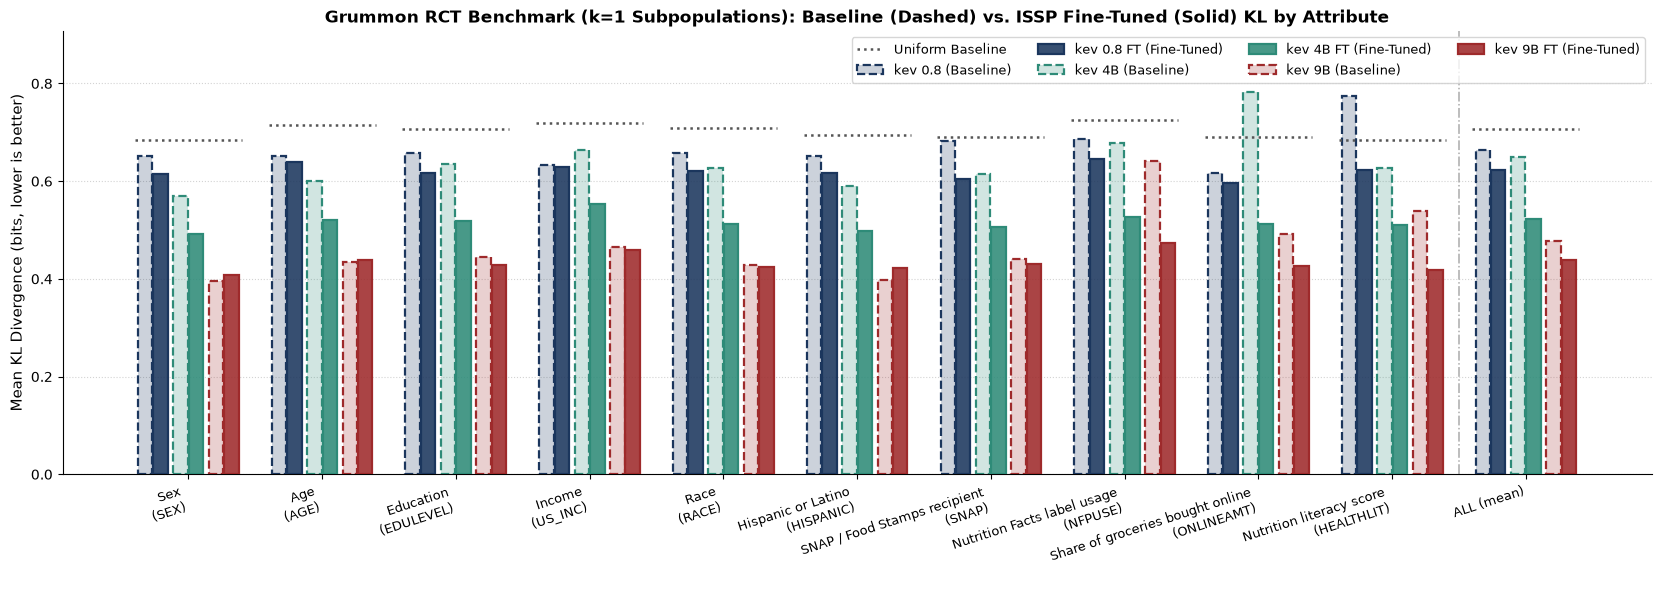

In [19]:
from matplotlib.colors import to_rgba

attrs = list(attr_kl_df.index)
x = np.arange(len(attrs), dtype=float)

size_groups = [
    ("0.8B", "kev 0.8", "kev 0.8 FT", LANCET_PALETTE[0]),
    ("4B", "kev 4B", "kev 4B FT", LANCET_PALETTE[2]),
    ("9B", "kev 9B", "kev 9B FT", LANCET_PALETTE[1]),
]

bar_w = 0.115
pair_gap = 0.035
group_span = 2 * bar_w
group_step = group_span + pair_gap
group_centers = (np.arange(len(size_groups)) - (len(size_groups) - 1) / 2.0) * group_step

fig, ax = plt.subplots(figsize=(16.5, 5.8), constrained_layout=True)

for g_idx, (size_name, base_col, ft_col, color) in enumerate(size_groups):
    c_offset = group_centers[g_idx]
    base_pos = x + c_offset - bar_w / 2.0
    ft_pos = x + c_offset + bar_w / 2.0

    ax.bar(
        base_pos,
        attr_kl_df[base_col].values,
        width=bar_w * 0.94,
        facecolor=to_rgba(color, 0.22),
        edgecolor=to_rgba(color, 1.0),
        linewidth=1.6,
        linestyle="--",
        label=f"{base_col} (Baseline)",
        zorder=3,
    )
    ax.bar(
        ft_pos,
        attr_kl_df[ft_col].values,
        width=bar_w * 0.94,
        facecolor=to_rgba(color, 0.88),
        edgecolor=to_rgba(color, 1.0),
        linewidth=1.6,
        linestyle="-",
        label=f"{ft_col} (Fine-Tuned)",
        zorder=3,
    )

# Plot Uniform reference ticks above each attribute super-group
half_cluster = group_centers[-1] + bar_w + 0.02
for i, u_val in enumerate(attr_kl_df["Uniform"].values):
    ax.hlines(
        u_val,
        x[i] - half_cluster,
        x[i] + half_cluster,
        colors="#555555",
        linestyles=":",
        linewidth=1.8,
        zorder=4,
        label="Uniform Baseline" if i == 0 else None,
    )

# Vertical separator before ALL (mean)
ax.axvline(len(attrs) - 1.5, color="#888888", linestyle="-.", linewidth=1.1, alpha=0.7)

xtick_labels = [
    f"{PERSONA_NAMES[a]}\n({a})" if a in PERSONA_NAMES else a
    for a in attrs
]
ax.set_xticks(x)
ax.set_xticklabels(xtick_labels, rotation=18, ha="right", fontsize=9.5)
ax.set_ylabel("Mean KL Divergence (bits, lower is better)", fontsize=11)
ax.set_title(
    "Grummon RCT Benchmark (k=1 Subpopulations): Baseline (Dashed) vs. ISSP Fine-Tuned (Solid) KL by Attribute",
    fontsize=12.5,
    fontweight="bold",
)
ax.set_ylim(0, max(attr_kl_df[model_cols].max()) * 1.16)
ax.grid(axis="y", linestyle=":", alpha=0.55, zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(ncol=4, frameon=True, fontsize=9.5, loc="upper right")
plt.show()

In [ ]:
from matplotlib.colors import to_rgba

# In-Training attributes (present in US-ISSP training data) vs. Out-of-Sample / New attributes (unseen during training)
IN_TRAIN_ATTRS = ["SEX", "AGE", "EDULEVEL", "US_INC"]
NEW_ATTRS = ["RACE", "HISPANIC", "SNAP", "NFPUSE", "ONLINEAMT", "HEALTHLIT"]

if set(IN_TRAIN_ATTRS + NEW_ATTRS) != set(DEMO_COLS):
    raise ValueError(f"Attribute partition mismatch: {set(IN_TRAIN_ATTRS + NEW_ATTRS) ^ set(DEMO_COLS)}")

in_train_mask = kl_k1_df["attribute"].isin(IN_TRAIN_ATTRS)
new_attr_mask = kl_k1_df["attribute"].isin(NEW_ATTRS)

grouped_attr_kl_df = pd.concat([
    attr_kl_df.loc[IN_TRAIN_ATTRS],
    pd.DataFrame([kl_k1_df.loc[in_train_mask, model_cols].mean()], index=["In-Training (mean)"]),
    attr_kl_df.loc[NEW_ATTRS],
    pd.DataFrame([kl_k1_df.loc[new_attr_mask, model_cols].mean()], index=["Out-of-Sample (mean)"]),
    pd.DataFrame([kl_k1_df[model_cols].mean()], index=["ALL (mean)"]),
])

print("=== Mean KL: In-Training (ISSP) vs. Out-of-Sample (New) Persona Attributes ===")
display(
    grouped_attr_kl_df.loc[["In-Training (mean)", "Out-of-Sample (mean)", "ALL (mean)"]].round(4)
)

plot_rows = list(grouped_attr_kl_df.index)
# Add visual spacing gaps between the 3 sections: In-Training (5 bars), Out-of-Sample (7 bars), ALL (1 bar)
n_in = len(IN_TRAIN_ATTRS) + 1
n_new = len(NEW_ATTRS) + 1
section_gap = 0.55

x_grouped = np.concatenate([
    np.arange(n_in, dtype=float),
    np.arange(n_in, n_in + n_new, dtype=float) + section_gap,
    np.array([n_in + n_new + 2 * section_gap], dtype=float),
])

size_groups = [
    ("0.8B", "kev 0.8", "kev 0.8 FT", LANCET_PALETTE[0]),
    ("4B", "kev 4B", "kev 4B FT", LANCET_PALETTE[2]),
    ("9B", "kev 9B", "kev 9B FT", LANCET_PALETTE[1]),
]

bar_w = 0.115
pair_gap = 0.035
group_step = 2 * bar_w + pair_gap
group_centers = (np.arange(len(size_groups)) - (len(size_groups) - 1) / 2.0) * group_step

fig, ax = plt.subplots(figsize=(18.5, 6.2), constrained_layout=True)

y_max = float(grouped_attr_kl_df[model_cols].to_numpy().max()) * 1.22

# Subtle background spans for the two attribute regimes
in_left, in_right = x_grouped[0] - 0.48, x_grouped[n_in - 1] + 0.48
new_left, new_right = x_grouped[n_in] - 0.48, x_grouped[n_in + n_new - 1] + 0.48
ax.axvspan(in_left, in_right, color=LANCET_PALETTE[0], alpha=0.045, zorder=0)
ax.axvspan(new_left, new_right, color=LANCET_PALETTE[3], alpha=0.055, zorder=0)

for g_idx, (size_name, base_col, ft_col, color) in enumerate(size_groups):
    c_offset = group_centers[g_idx]
    base_pos = x_grouped + c_offset - bar_w / 2.0
    ft_pos = x_grouped + c_offset + bar_w / 2.0

    ax.bar(
        base_pos,
        grouped_attr_kl_df[base_col].values,
        width=bar_w * 0.94,
        facecolor=to_rgba(color, 0.22),
        edgecolor=to_rgba(color, 1.0),
        linewidth=1.6,
        linestyle="--",
        label=f"{base_col} (Baseline)",
        zorder=3,
    )
    ax.bar(
        ft_pos,
        grouped_attr_kl_df[ft_col].values,
        width=bar_w * 0.94,
        facecolor=to_rgba(color, 0.88),
        edgecolor=to_rgba(color, 1.0),
        linewidth=1.6,
        linestyle="-",
        label=f"{ft_col} (Fine-Tuned)",
        zorder=3,
    )

half_cluster = group_centers[-1] + bar_w + 0.02
for i, u_val in enumerate(grouped_attr_kl_df["Uniform"].values):
    ax.hlines(
        u_val,
        x_grouped[i] - half_cluster,
        x_grouped[i] + half_cluster,
        colors="#555555",
        linestyles=":",
        linewidth=1.8,
        zorder=4,
        label="Uniform Baseline" if i == 0 else None,
    )

# Dividers between sections and before each section's summary mean
ax.axvline((x_grouped[n_in - 2] + x_grouped[n_in - 1]) / 2.0, color="#999999", linestyle=":", linewidth=1.0, alpha=0.8)
ax.axvline((x_grouped[n_in - 1] + x_grouped[n_in]) / 2.0, color="#444444", linestyle="--", linewidth=1.4, alpha=0.85)
ax.axvline((x_grouped[n_in + n_new - 2] + x_grouped[n_in + n_new - 1]) / 2.0, color="#999999", linestyle=":", linewidth=1.0, alpha=0.8)
ax.axvline((x_grouped[n_in + n_new - 1] + x_grouped[-1]) / 2.0, color="#444444", linestyle="--", linewidth=1.4, alpha=0.85)

# Section header banners
ax.text(
    (in_left + in_right) / 2.0,
    y_max * 0.94,
    "In-Training Persona Attributes (Seen in ISSP Fine-Tuning)",
    ha="center",
    va="center",
    fontsize=10.5,
    fontweight="bold",
    color=LANCET_PALETTE[0],
    bbox={"boxstyle": "round,pad=0.3", "facecolor": "white", "edgecolor": LANCET_PALETTE[0], "alpha": 0.9},
)
ax.text(
    (new_left + new_right) / 2.0,
    y_max * 0.94,
    "Out-of-Sample / New Persona Attributes (Unseen in ISSP Fine-Tuning)",
    ha="center",
    va="center",
    fontsize=10.5,
    fontweight="bold",
    color="#8C4A08",
    bbox={"boxstyle": "round,pad=0.3", "facecolor": "white", "edgecolor": LANCET_PALETTE[3], "alpha": 0.9},
)

xtick_labels = [
    f"{PERSONA_NAMES[a]}\n({a})" if a in PERSONA_NAMES else a
    for a in plot_rows
]
ax.set_xticks(x_grouped)
ax.set_xticklabels(xtick_labels, rotation=18, ha="right", fontsize=9.5)
for tick_lbl, r_name in zip(ax.get_xticklabels(), plot_rows):
    if "mean" in r_name:
        tick_lbl.set_fontweight("bold")

ax.set_xlim(in_left - 0.15, x_grouped[-1] + 0.55)
ax.set_ylim(0, y_max)
ax.set_ylabel("Mean KL Divergence (bits, lower is better)", fontsize=11)
ax.set_title(
    "Grummon RCT Benchmark (k=1): Baseline (Dashed) vs. Fine-Tuned (Solid) KL — In-Training vs. Out-of-Sample Persona Attributes",
    fontsize=12.5,
    fontweight="bold",
)
ax.grid(axis="y", linestyle=":", alpha=0.55, zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(ncol=4, frameon=True, fontsize=9.2, loc="upper right")
plt.show()

In [13]:
print("=== Mean KL by Trial Arm (eval_records_k1) ===")
arm_kl_df = kl_k1_df.groupby("arm", sort=False)[model_cols].mean()
arm_kl_df.loc["ALL (mean)"] = kl_k1_df[model_cols].mean()
display(arm_kl_df.round(4))

=== Mean KL by Trial Arm (eval_records_k1) ===


,Uniform,kev 0.8,kev 0.8 FT,kev 4B,kev 4B FT,kev 9B,kev 9B FT
arm,,,,,,,
Positive,0.7941,0.8162,0.7048,0.7086,0.5459,0.5419,0.4795
Positive+NutritionInfo,0.7708,0.6406,0.6409,0.6015,0.5095,0.4855,0.4465
Positive+HighIn,0.7059,0.6459,0.6416,0.7026,0.5669,0.4574,0.4649
HighIn,0.6108,0.5600,0.5930,0.5834,0.5081,0.3899,0.4315
Spectrum,0.6413,0.7168,0.5526,0.7206,0.5161,0.5497,0.3980
NutritionInfo,0.7201,0.6062,0.6094,0.5831,0.4901,0.4488,0.4128
ALL (mean),0.7061,0.6633,0.6231,0.6495,0.5225,0.4783,0.4385


In [14]:
print("=== Mean KL by Survey Item (eval_records_k1) ===")
item_kl_df = kl_k1_df.groupby(["type", "v"], sort=False)[model_cols].mean()
display(item_kl_df.round(4))

=== Mean KL by Survey Item (eval_records_k1) ===


Uniform  kev 0.8  kev 0.8 FT  kev 4B  kev 4B FT  \
type   v                                                                    
choice idbev               0.6958   0.7705      0.8443  0.9309     0.8473   
       idbread             0.5662   0.6464      0.7019  0.5347     0.5148   
       idcereal            1.0595   1.3968      1.3110  1.3908     1.2007   
       idsoup              0.5497   0.5164      0.5264  0.5678     0.6135   
       idsnack             0.9327   0.8726      1.0380  0.9684     0.8665   
       idmeal              0.3163   0.2589      0.3184  0.3043     0.2961   
       rnoticed_trial      0.0646   0.1222      0.0398  0.1092     0.0305   
       rused_trial         0.0306   0.0580      0.0556  0.0721     0.0583   
score  elaborationhealth   0.2294   0.1516      0.1089  0.1897     0.1967   
       raffect_worried     0.7324   0.5749      0.4380  0.4317     0.4192   
       raffect_scared      1.1530   0.9165      0.8507  0.5997     0.6828   
       raffect_guilty      0.6074   0.4153      0.3538  0.2576     0.2287   
       raffect_ashamed     0.9196   0.7514      0.6909  0.5945     0.4509   
       raffect_sad         1.1672   0.9391      0.8167  0.6898     0.6008   
       rhelp               0.5363   0.1722      0.2639  0.3556     0.1741   
       runderstand         0.7632   1.1161      0.7108  0.5871     0.4579   
       rtrust              0.7323   0.7227      0.4736  0.4450     0.3196   
       rsupport            0.4965   0.4781      0.4270  0.3954     0.2824   
       feltreal            0.7048   0.2927      0.4601  0.6196     0.4528   
       picksimilar         1.2191   1.2984      1.2386  1.7590     1.0730   
       similarusual        1.1752   1.3008      1.2677  1.6843     1.0850   

                          kev 9B  kev 9B FT  
type   v                                     
choice idbev              0.6286     0.5627  
       idbread            0.5672     0.4792  
       idcereal           0.6321     0.9493  
       idsoup             0.6198     0.4831  
       idsnack            0.5112     0.6803  
       idmeal             0.2733     0.2241  
       rnoticed_trial     0.4171     0.0349  
       rused_trial        0.1108     0.0412  
score  elaborationhealth  0.3030     0.1718  
       raffect_worried    0.3615     0.3617  
       raffect_scared     0.5193     0.5432  
       raffect_guilty     0.3052     0.1954  
       raffect_ashamed    0.4097     0.3333  
       raffect_sad        0.6473     0.4403  
       rhelp              0.2290     0.1882  
       runderstand        0.3667     0.5961  
       rtrust             0.3030     0.2496  
       rsupport           0.3975     0.2715  
       feltreal           0.3172     0.3649  
       picksimilar        1.2435     1.1248  
       similarusual       0.7842     0.8094

In [15]:
# Win-rate (% of k=1 subpopulation-question records where Fine-Tuned KL < Baseline KL)
win_rates = {}
for size_label, base_col, ft_col in [
    ("0.8B (FT vs Baseline)", "kev 0.8", "kev 0.8 FT"),
    ("4B (FT vs Baseline)", "kev 4B", "kev 4B FT"),
    ("9B (FT vs Baseline)", "kev 9B", "kev 9B FT"),
]:
    win_rates[size_label] = {
        "All records (%)": float((kl_k1_df[ft_col] < kl_k1_df[base_col]).mean() * 100.0),
        "Choice records (%)": float((kl_k1_df.loc[kl_k1_df["type"] == "choice", ft_col] < kl_k1_df.loc[kl_k1_df["type"] == "choice", base_col]).mean() * 100.0),
        "Score records (%)": float((kl_k1_df.loc[kl_k1_df["type"] == "score", ft_col] < kl_k1_df.loc[kl_k1_df["type"] == "score", base_col]).mean() * 100.0),
    }
print("=== Fine-Tuned vs. Baseline KL Win Rate on eval_records_k1 ===")
display(pd.DataFrame(win_rates).T.round(2))

=== Fine-Tuned vs. Baseline KL Win Rate on eval_records_k1 ===


,All records (%),Choice records (%),Score records (%)
0.8B (FT vs Baseline),57.08,44.17,64.75
4B (FT vs Baseline),66.92,58.00,72.23
9B (FT vs Baseline),55.34,52.44,57.06


## 4. Future Implementation: Silicon-Sampling Regression & Hypothesis-Testing Benchmark

### Objective
Test whether replacing human RCT participants with decision models (off-the-shelf vs. US-ISSP fine-tuned Kev `0.8B`, `4B`, `9B`) reproduces the substantive **treatment-effect regression coefficients ($\hat{\beta}$), standard errors, hypothesis test results ($p$-values), and policy rankings** reported in Grummon et al. (2025, `Supplement 2, eTable 9`, p. 18).

---

### 1. Primary Regression to Replicate: Consumer Understanding (`idbev`–`idmeal`, `eTable 9` Row 1)
- **Task & Stimulus**: Across the 6 pairwise product-healthfulness `choice` tasks (`idbev`, `idbread`, `idcereal`, `idsoup`, `idsnack`, `idmeal`), each participant sees two real products side by side with their assigned trial arm's front-of-package label in `criteria` and selects **Option 1 (healthier product)**, **Option 2 (less healthy product)**, or **Option 3 ("They're the same")**.
- **Dependent Variable (DV)**:
  - **Human**: Binary indicator $y_{ij}^{\text{human}} = \mathbb{1}[\text{chose Option 1}] \in \{0, 1\}$ (`scr_idbev`..`scr_idmeal`), or participant-level mean accuracy $\bar{y}_i^{\text{human}} = \frac{1}{6}\sum_{j=1}^6 y_{ij}^{\text{human}} \in [0, 1]$.
  - **Decision Model (Expected Probability)**: Predicted probability placed on Option 1, $\hat{p}_{ij} = P_{\text{model}}(\text{Option 1} \mid s_i, a_i, q_j)$, averaged per participant $\hat{y}_i^{\text{prob}} = \frac{1}{6}\sum_{j=1}^6 \hat{p}_{ij}$.
  - **Decision Model (Silicon-Sampled Discrete Draws)**: For each participant $i$ and item $j$, draw $y_{ij}^{\text{sim}} \sim \text{Bernoulli}(\hat{p}_{ij})$ (exact 1-for-1 sample size $N = 5,636$).
- **Independent Variables (IVs)**: The 5 intervention arm indicators with **`Positive` (current 1–3 star Guiding Stars) as the reference category ($0$)**:
  $$Y_i = \beta_0 + \beta_1 \text{NutritionInfo}_i + \beta_2 \text{HighIn}_i + \beta_3 \text{Pos+NutrInfo}_i + \beta_4 \text{Pos+HighIn}_i + \beta_5 \text{Spectrum}_i + \varepsilon_i$$
- **Human Ground-Truth Benchmark (`ParentFile_wide.csv` / `eTable 9`)**:
  - Reference (`Positive`): $\hat{\beta}_0 = 0.631$
  - **Tier 1 (Largest gain)**: `NutritionInfo` ($\hat{\beta}_1 = +0.184, p < .001$) and `Positive+NutritionInfo` ($\hat{\beta}_3 = +0.179, p < .001$)
  - **Tier 2 (Medium gain)**: `Positive+HighIn` ($\hat{\beta}_4 = +0.118, p < .001$) and `Spectrum` ($\hat{\beta}_5 = +0.108, p < .001$)
  - **Tier 3 (Smallest gain)**: `HighIn` ($\hat{\beta}_2 = +0.053, p < .001$)

---

### 2. Secondary Regression (Optional Subjective Likert Comparison): Perceived Helpfulness (`rhelp`, `eTable 9`)
- **DV**: 5-point Likert rating ($1 = \text{Strongly disagree} \dots 5 = \text{Strongly agree}$). For the decision model, use expected score $\hat{y}_i = \sum_{k=1}^5 k \, p_{i,k}$ and discrete draws $y_i^{\text{sim}} \sim \text{Categorical}(\mathbf{p}_i)$.
- **Human Ground Truth (`eTable 9`)**: Strong positive ADEs for `NutritionInfo` ($+0.44, p < .05$), `HighIn` ($+0.40, p < .05$), `Positive+NutritionInfo` ($+0.38, p < .05$), and `Positive+HighIn` ($+0.37, p < .05$), vs. a much smaller ADE for `Spectrum` ($+0.17, p < .05$).

---

### 3. Step-by-Step Implementation Plan
1. **Build unique respondent `(arm, persona)` queries**:
   - Map each of the $N = 5,636$ participants in `resp_df` to their demographic `state` ($k=1$ or full multi-attribute persona) and assigned trial arm (`arm`).
   - Deduplicate unique `(arm, state)` profiles before running `predict_probs` (only ~2,700–5,200 unique profiles), then map predicted probability vectors $\mathbf{p}_{ij}$ back to all $5,636$ rows.
2. **Run models**:
   - Off-the-shelf: `kev 0.8`, `kev 0.8 (T=1)`, `kev 4B`, `kev 4B (T=1)`, `kev 9B`, `kev 9B (T=1)`.
   - Fine-tuned: `kev 0.8 FT`, `kev 4B FT`, `kev 9B FT`.
3. **Estimate OLS / Mixed-Effects regressions and compare against Human**:
   - Compare the 5 estimated treatment effects ($\hat{\beta}_1 \dots \hat{\beta}_5$), $95\%$ CIs, and $p$-values side by side.
   - Report: (a) **Sign & significance agreement rate** (out of 5 arms), (b) **Spearman rank correlation** of arm treatment effects vs. Human, and (c) **MAE / RMSE on $\hat{\beta}$** across models.